In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import random

from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [27]:
path = r"C:\Users\PRASANNA\OneDrive\Attachments\Desktop\DL datasets\Fashion MNIST"

train_data = pd.read_csv(path + r"\fashion-mnist_train.csv")
test_data = pd.read_csv(path + r"\fashion-mnist_test.csv")

In [31]:
 print(train_data.shape)
 print(test_data.shape)

(60000, 785)
(10000, 785)


In [32]:
x_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

print(x_train.shape)
print( y_train.shape)
print(x_test.shape)
print( y_test.shape)

(60000, 784)
(60000,)
(10000, 784)
(10000,)


In [10]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

In [11]:
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training Images Shape:", x_train.shape)
print("Testing Images Shape:", x_test.shape)

Training Images Shape: (60000, 28, 28, 1)
Testing Images Shape: (10000, 28, 28, 1)


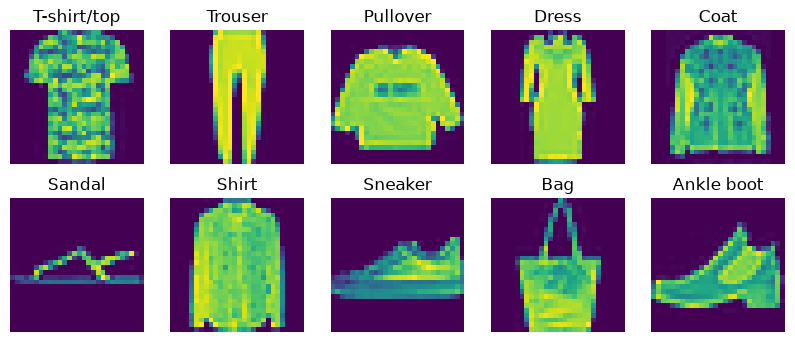

In [13]:
plt.figure(figsize=(10, 4))

for i in range(10):
    n = np.where(y_train == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[n].reshape(28, 28))
    plt.title(class_names[i])
    plt.axis('off')
plt.show()

In [15]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [16]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training Data:", x_train.shape)
print("Training Labels:", y_train.shape)
print("Validation Data:", x_val.shape)
print("Validation Labels:", y_val.shape)

Training Data: (54000, 28, 28, 1)
Training Labels: (54000,)
Validation Data: (6000, 28, 28, 1)
Validation Labels: (6000,)


In [17]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

C:\Users\PRASANNA\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [19]:
h = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=128
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - accuracy: 0.5778 - loss: 1.1767 - val_accuracy: 0.7182 - val_loss: 0.7521
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.7327 - loss: 0.7095 - val_accuracy: 0.7432 - val_loss: 0.6965
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.7558 - loss: 0.6470 - val_accuracy: 0.7620 - val_loss: 0.6252
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.7716 - loss: 0.6012 - val_accuracy: 0.7660 - val_loss: 0.5971
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.7884 - loss: 0.5611 - val_accuracy: 0.7757 - val_loss: 0.5927
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.7983 - loss: 0.5363 - val_accuracy: 0.8010 - val_loss: 0.5409
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.8079 - loss: 0.5133 - val_accuracy: 0.8095 - val_loss: 0.5108
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.8151 - loss: 0.4963 - val

In [20]:
test_loss, test_acc = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8373 - loss: 0.4513
Test Loss: 0.45129144191741943
Test Accuracy: 83.73000025749207 %


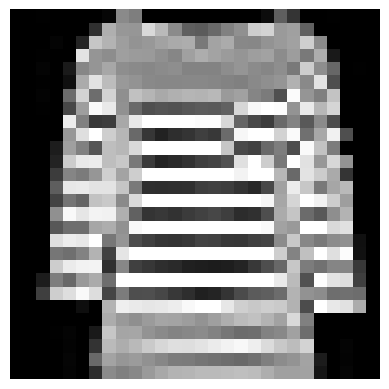

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Actual Class: Pullover
Predicted Class: Pullover


In [25]:
n = random.randint(0, len(x_test) - 1)

plt.imshow(x_test[n].reshape(28, 28),cmap='gray')
plt.axis('off')
plt.show()

pred = model.predict(
    x_test[n].reshape(1, 28, 28, 1),
)

print("Actual Class:", class_names[y_test[n]])
print("Predicted Class:", class_names[np.argmax(pred)])

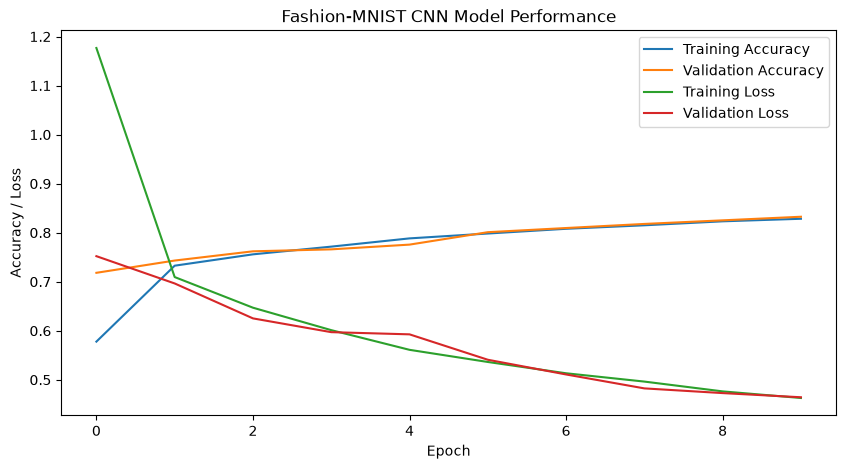

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(h.history['accuracy'], label='Training Accuracy')
plt.plot(h.history['val_accuracy'], label='Validation Accuracy')
plt.plot(h.history['loss'], label='Training Loss')
plt.plot(h.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Accuracy / Loss')
plt.title('Fashion-MNIST CNN Model Performance')

plt.legend()
plt.show()